# Module 7: Neural Network with Backpropagation

This notebook implements `TwoLayerNetBackprop`, a two-layer neural network built from layers that each have a
`forward` and a `backward` method, and trains and tests it on **MNIST** (loaded through Keras).

The class provides **both gradient approaches**:

* `gradient()`: **backpropagation** (forward pass, then a backward pass through the layers)
* `numerical_gradient()`: **numerical gradient** (central differences, the approach from the previous module)

Network: `784 -> Affine -> Sigmoid -> 50 -> Affine -> SoftmaxWithLoss -> 10`.

Plan:
1. Load MNIST with Keras and prepare the data.
2. Implement the layers and `TwoLayerNetBackprop`.
3. **Gradient check**: backpropagation vs numerical gradient on the real network and real images.
4. **Experiment A (same budget)**: train two identical networks with the same initial weights and the same mini-batches,
   one with the numerical gradient and one with backpropagation, and compare accuracy and time.
5. **Experiment B (full training)**: train with backpropagation for many epochs and report train/test accuracy.
6. Test results: actual vs predicted classes, per-class accuracy, confusion matrix, example images.
7. Summary of both approaches.

## 1. Setup and MNIST data (Keras)

In [1]:
import os
import time

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"       # keep TensorFlow's start-up messages out of the output
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
data source: tensorflow.keras.datasets.mnist
X_train: (60000, 28, 28) uint8   y_train: (60000,)
X_test:  (10000, 28, 28) uint8   y_test:  (10000,)
train class counts: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]
test class counts:  [ 980 1135 1032 1010  982  892  958 1028  974 1009]


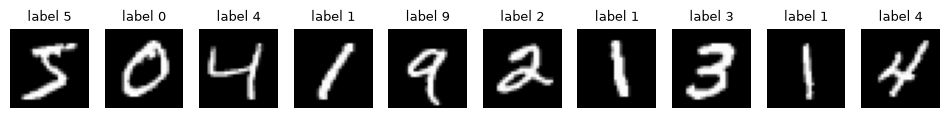

In [2]:
try:
    from tensorflow.keras.datasets import mnist

    (X_train, y_train), (X_test, y_test) = mnist.load_data()
    data_source = "tensorflow.keras.datasets.mnist"
except ImportError:
    # TensorFlow is not installed in this environment: read the same mnist.npz file that Keras downloads.
    with np.load("mnist.npz") as f:
        X_train, y_train, X_test, y_test = f["x_train"], f["y_train"], f["x_test"], f["y_test"]
    data_source = "mnist.npz (the file Keras downloads)"

print("data source:", data_source)
print("X_train:", X_train.shape, X_train.dtype, "  y_train:", y_train.shape)
print("X_test: ", X_test.shape, X_test.dtype, "  y_test: ", y_test.shape)
print("train class counts:", np.bincount(y_train))
print("test class counts: ", np.bincount(y_test))

fig, axes = plt.subplots(1, 10, figsize=(12, 1.8))
for k, a in enumerate(axes):
    a.imshow(X_train[k], cmap="gray")
    a.set_title(f"label {y_train[k]}", fontsize=9)
    a.axis("off")
plt.show()


Preprocessing: flatten each 28x28 image to 784 values, scale pixels from 0-255 to 0-1, and one-hot encode the labels.

In [3]:
x_train = X_train.reshape(-1, 784).astype(np.float64) / 255.0
x_test = X_test.reshape(-1, 784).astype(np.float64) / 255.0
t_train = np.eye(10)[y_train]
t_test = np.eye(10)[y_test]
print(x_train.shape, x_test.shape, t_train.shape, t_test.shape)
print("pixel range:", x_train.min(), "to", x_train.max())


(60000, 784) (10000, 784) (60000, 10) (10000, 10)
pixel range: 0.0 to 1.0


## 2. Implementation

### Helper functions

In [4]:
import numpy as np
from collections import OrderedDict


# ----------------------------------------------------------------------------
# Helper functions


### Layers

Each layer's `forward` computes its output and remembers what `backward` needs. `backward(dout)` receives the gradient of the loss with respect to the layer's output and returns the gradient with respect to its input (and stores `dW`, `db` for `Affine`).

In [5]:
# ----------------------------------------------------------------------------
def softmax(a):
    a = a - np.max(a, axis=-1, keepdims=True)      # subtract the row max for numerical stability
    e = np.exp(a)
    return e / np.sum(e, axis=-1, keepdims=True)


def cross_entropy_error(y, t):
    """Mean cross-entropy between predicted probabilities y and one-hot targets t."""
    if y.ndim == 1:
        y, t = y.reshape(1, -1), t.reshape(1, -1)
    return -np.sum(t * np.log(y + 1e-7)) / y.shape[0]


def numerical_gradient(f, x, h=1e-4):
    """Central-difference gradient of f with respect to the array x (changed in place, then restored)."""
    grad = np.zeros_like(x)
    it = np.nditer(x, flags=["multi_index"], op_flags=["readwrite"])
    while not it.finished:
        idx = it.multi_index
        original = x[idx]

        x[idx] = original + h
        f_plus = f(x)

        x[idx] = original - h
        f_minus = f(x)

        grad[idx] = (f_plus - f_minus) / (2 * h)
        x[idx] = original
        it.iternext()
    return grad


# ----------------------------------------------------------------------------
# Layers: each has forward(...) and backward(dout)


### `TwoLayerNetBackprop`

`predict` is the **forward propagation** (Affine1 -> Sigmoid -> Affine2). `gradient` runs the forward pass through `loss`, then the **backward propagation** through the layers in reverse order.

In [6]:
# ----------------------------------------------------------------------------
class Affine:
    """y = x @ W + b"""

    def __init__(self, W, b):
        self.W, self.b = W, b
        self.x = None
        self.dW, self.db = None, None

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, dout):
        self.dW = self.x.T @ dout            # dL/dW
        self.db = np.sum(dout, axis=0)       # dL/db
        return dout @ self.W.T               # dL/dx, passed to the previous layer


class Sigmoid:
    """y = 1 / (1 + exp(-x))"""

    def __init__(self):
        self.out = None

    def forward(self, x):
        self.out = 1.0 / (1.0 + np.exp(-x))
        return self.out

    def backward(self, dout):
        return dout * self.out * (1.0 - self.out)    # sigma'(x) = sigma(x) * (1 - sigma(x))


class SoftmaxWithLoss:
    """Softmax followed by cross-entropy loss (one-hot targets)."""

    def __init__(self):
        self.loss, self.y, self.t = None, None, None

    def forward(self, x, t):
        self.t = t
        self.y = softmax(x)
        self.loss = cross_entropy_error(self.y, self.t)
        return self.loss

    def backward(self, dout=1):
        batch_size = self.t.shape[0]
        return dout * (self.y - self.t) / batch_size  # combined gradient of softmax + cross-entropy


# ----------------------------------------------------------------------------
# The network
# ----------------------------------------------------------------------------
class TwoLayerNetBackprop:
    """input -> Affine1 -> Sigmoid -> Affine2 -> SoftmaxWithLoss

    gradient()            : backpropagation (forward pass, then backward pass through the layers)
    numerical_gradient()  : central differences, used to check gradient() and as the slow baseline
    """

    def __init__(self, input_size, hidden_size, output_size, weight_init_std=0.1, seed=0):
        rng = np.random.default_rng(seed)
        self.params = {
            "W1": weight_init_std * rng.standard_normal((input_size, hidden_size)),
            "b1": np.zeros(hidden_size),
            "W2": weight_init_std * rng.standard_normal((hidden_size, output_size)),
            "b2": np.zeros(output_size),
        }
        self.layers = OrderedDict()
        self.layers["Affine1"] = Affine(self.params["W1"], self.params["b1"])
        self.layers["Sigmoid1"] = Sigmoid()
        self.layers["Affine2"] = Affine(self.params["W2"], self.params["b2"])
        self.last_layer = SoftmaxWithLoss()

    # ---- forward propagation ------------------------------------------------
    def predict(self, x):
        """Forward pass through the layers; returns the class scores (logits)."""
        for layer in self.layers.values():
            x = layer.forward(x)
        return x

    def loss(self, x, t):
        return self.last_layer.forward(self.predict(x), t)

    def accuracy(self, x, t):
        y = np.argmax(self.predict(x), axis=1)
        return float(np.mean(y == np.argmax(t, axis=1)))

    # ---- gradients ----------------------------------------------------------
    def numerical_gradient(self, x, t):
        loss_W = lambda _: self.loss(x, t)           # the parameter array is changed in place
        return {key: numerical_gradient(loss_W, value) for key, value in self.params.items()}

    def gradient(self, x, t):
        self.loss(x, t)                               # forward pass (stores what backward needs)

        dout = self.last_layer.backward(1)            # backward pass, last layer first
        for layer in reversed(list(self.layers.values())):
            dout = layer.backward(dout)

        return {
            "W1": self.layers["Affine1"].dW, "b1": self.layers["Affine1"].db,
            "W2": self.layers["Affine2"].dW, "b2": self.layers["Affine2"].db,
        }


## 3. Gradient check on the real network

Backpropagation is only trustworthy if it agrees with the (slow but simple) numerical gradient. Here both are computed for the full 784-50-10 network on three real MNIST images. They should agree closely; the remaining tiny difference (relative error around 1e-6) comes from the finite step `h` and from the small `1e-7` added inside the `log` of the cross-entropy, which the analytic formula ignores.

In [7]:
check_net = TwoLayerNetBackprop(784, 50, 10, weight_init_std=0.1, seed=0)
n_params = sum(v.size for v in check_net.params.values())
xb, tb = x_train[:3], t_train[:3]

t0 = time.perf_counter()
grad_numerical = check_net.numerical_gradient(xb, tb)
time_numerical = time.perf_counter() - t0

t0 = time.perf_counter()
grad_backprop = check_net.gradient(xb, tb)
time_backprop = time.perf_counter() - t0

print(f"parameters: {n_params}")
for key in grad_numerical:
    diff = np.abs(grad_numerical[key] - grad_backprop[key])
    rel = diff.max() / np.abs(grad_backprop[key]).max()          # error relative to the largest gradient entry
    print(f"{key}: mean |numerical - backprop| = {diff.mean():.2e}   max = {diff.max():.2e}   relative max error = {rel:.1e}")
    assert rel < 1e-4
print(f"\nnumerical gradient: {time_numerical:.2f} s    backpropagation: {time_backprop * 1000:.2f} ms    "
      f"(backprop is about {time_numerical / time_backprop:,.0f}x faster)")


parameters: 39760
W1: mean |numerical - backprop| = 4.27e-09   max = 7.49e-08   relative max error = 2.3e-06
b1: mean |numerical - backprop| = 2.66e-08   max = 7.55e-08   relative max error = 2.3e-06
W2: mean |numerical - backprop| = 1.36e-07   max = 1.13e-06   relative max error = 3.8e-06
b2: mean |numerical - backprop| = 2.74e-07   max = 1.19e-06   relative max error = 3.9e-06

numerical gradient: 3.11 s    backpropagation: 0.31 ms    (backprop is about 10,182x faster)


## 4. Experiment A: numerical gradient vs backpropagation with the same budget

Both networks start from **identical weights** and see the **identical sequence of mini-batches**, with the same learning rate. The only difference is how the gradient is computed. Because the numerical gradient costs two forward passes per parameter (about 80,000 per step for this network), this experiment is short.

In [8]:
A_ITERS = 100
A_BATCH = 32
A_LR = 1.0
A_STD = 0.1

batch_rng = np.random.default_rng(0)
batches = [batch_rng.choice(len(x_train), A_BATCH) for _ in range(A_ITERS)]   # same batches for both runs


def train_fixed(net, grad_method, log_every):
    losses = []
    start = time.perf_counter()
    for i, mask in enumerate(batches, 1):
        xb, tb = x_train[mask], t_train[mask]
        grad = getattr(net, grad_method)(xb, tb)
        for key in net.params:
            net.params[key] -= A_LR * grad[key]
        losses.append(net.loss(xb, tb))
        if i % log_every == 0:
            print(f"  iter {i:4d}/{A_ITERS}   batch loss {losses[-1]:.4f}   ({time.perf_counter() - start:.1f}s elapsed)")
    return losses, time.perf_counter() - start


net_bp_A = TwoLayerNetBackprop(784, 50, 10, weight_init_std=A_STD, seed=0)
net_num_A = TwoLayerNetBackprop(784, 50, 10, weight_init_std=A_STD, seed=0)
assert all(np.array_equal(net_bp_A.params[k], net_num_A.params[k]) for k in net_bp_A.params)
print(f"initial test accuracy (both networks): {net_bp_A.accuracy(x_test, t_test):.4f}\n")

print("Backpropagation:")
loss_bp_A, time_bp_A = train_fixed(net_bp_A, "gradient", log_every=max(A_ITERS // 5, 1))
print("\nNumerical gradient:")
loss_num_A, time_num_A = train_fixed(net_num_A, "numerical_gradient", log_every=max(A_ITERS // 10, 1))


initial test accuracy (both networks): 0.1194

Backpropagation:
  iter   20/100   batch loss 1.1365   (0.0s elapsed)
  iter   40/100   batch loss 0.6574   (0.0s elapsed)
  iter   60/100   batch loss 0.5537   (0.0s elapsed)
  iter   80/100   batch loss 0.4161   (0.0s elapsed)
  iter  100/100   batch loss 0.3297   (0.1s elapsed)

Numerical gradient:
  iter   10/100   batch loss 1.6494   (83.6s elapsed)
  iter   20/100   batch loss 1.1365   (174.7s elapsed)
  iter   30/100   batch loss 1.1138   (260.7s elapsed)
  iter   40/100   batch loss 0.6574   (342.8s elapsed)
  iter   50/100   batch loss 0.5314   (419.5s elapsed)
  iter   60/100   batch loss 0.5537   (509.5s elapsed)
  iter   70/100   batch loss 0.5320   (593.5s elapsed)
  iter   80/100   batch loss 0.4161   (676.5s elapsed)
  iter   90/100   batch loss 0.3628   (772.8s elapsed)
  iter  100/100   batch loss 0.3297   (859.4s elapsed)


,approach,iterations,training time (s),time per iteration (s),train accuracy,test accuracy
0,Numerical gradient,100,859.38,8.5938,0.8404,0.8406
1,Backpropagation,100,0.05,0.0005,0.8404,0.8406


largest weight difference between the two trained networks: 3.26e-06
speed-up of backpropagation: 16,991x


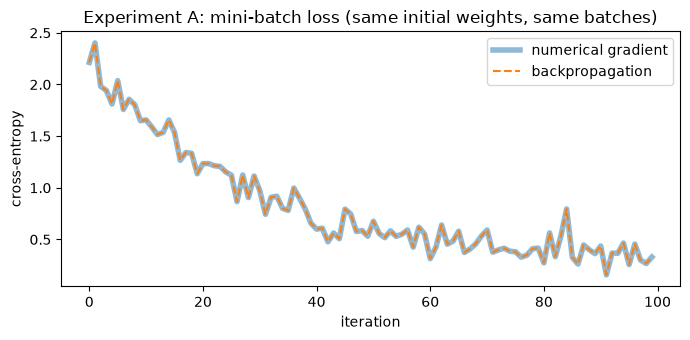

In [9]:
acc_rows = []
for name, net, secs in [("Numerical gradient", net_num_A, time_num_A), ("Backpropagation", net_bp_A, time_bp_A)]:
    acc_rows.append({
        "approach": name,
        "iterations": A_ITERS,
        "training time (s)": round(secs, 2),
        "time per iteration (s)": round(secs / A_ITERS, 4),
        "train accuracy": round(net.accuracy(x_train, t_train), 4),
        "test accuracy": round(net.accuracy(x_test, t_test), 4),
    })
display(pd.DataFrame(acc_rows))

max_diff = max(np.max(np.abs(net_num_A.params[k] - net_bp_A.params[k])) for k in net_bp_A.params)
print(f"largest weight difference between the two trained networks: {max_diff:.2e}")
print(f"speed-up of backpropagation: {time_num_A / time_bp_A:,.0f}x")

plt.figure(figsize=(7, 3.5))
plt.plot(loss_num_A, label="numerical gradient", linewidth=4, alpha=0.5)
plt.plot(loss_bp_A, label="backpropagation", linestyle="--")
plt.title("Experiment A: mini-batch loss (same initial weights, same batches)")
plt.xlabel("iteration")
plt.ylabel("cross-entropy")
plt.legend()
plt.tight_layout()
plt.show()


## 5. Experiment B: full training with backpropagation

Backpropagation is fast enough to train for many epochs (one epoch = one pass over all 60,000 training images). Batch size 100, learning rate 0.5; the training set is reshuffled every epoch. Training and test accuracy are recorded after every epoch.

In [10]:
B_EPOCHS = 20
B_BATCH = 100
B_LR = 0.5
B_STD = 0.1

net = TwoLayerNetBackprop(784, 50, 10, weight_init_std=B_STD, seed=0)
iters_per_epoch = len(x_train) // B_BATCH
rng = np.random.default_rng(0)

loss_history, train_acc_history, test_acc_history = [], [], []
print(f"initial accuracy   train {net.accuracy(x_train, t_train):.4f}   test {net.accuracy(x_test, t_test):.4f}")

start = time.perf_counter()
for epoch in range(1, B_EPOCHS + 1):
    order = rng.permutation(len(x_train))
    for j in range(iters_per_epoch):
        mask = order[j * B_BATCH:(j + 1) * B_BATCH]
        xb, tb = x_train[mask], t_train[mask]

        grad = net.gradient(xb, tb)                       # backpropagation
        for key in net.params:
            net.params[key] -= B_LR * grad[key]
        loss_history.append(net.last_layer.loss)

    train_acc_history.append(net.accuracy(x_train, t_train))
    test_acc_history.append(net.accuracy(x_test, t_test))
    print(f"epoch {epoch:2d}/{B_EPOCHS}   loss {np.mean(loss_history[-iters_per_epoch:]):.4f}   "
          f"train acc {train_acc_history[-1]:.4f}   test acc {test_acc_history[-1]:.4f}   ({time.perf_counter() - start:.0f}s)")
time_B = time.perf_counter() - start
print(f"\ntraining finished in {time_B:.1f} seconds ({B_EPOCHS * iters_per_epoch} iterations)")


initial accuracy   train 0.1170   test 0.1194
epoch  1/20   loss 0.5390   train acc 0.9173   test acc 0.9195   (1s)
epoch  2/20   loss 0.2613   train acc 0.9328   test acc 0.9320   (1s)
epoch  3/20   loss 0.2107   train acc 0.9481   test acc 0.9453   (2s)
epoch  4/20   loss 0.1794   train acc 0.9546   test acc 0.9517   (3s)
epoch  5/20   loss 0.1579   train acc 0.9579   test acc 0.9548   (4s)
epoch  6/20   loss 0.1413   train acc 0.9636   test acc 0.9580   (5s)
epoch  7/20   loss 0.1278   train acc 0.9669   test acc 0.9619   (6s)
epoch  8/20   loss 0.1174   train acc 0.9688   test acc 0.9629   (6s)
epoch  9/20   loss 0.1085   train acc 0.9720   test acc 0.9658   (7s)
epoch 10/20   loss 0.1008   train acc 0.9741   test acc 0.9664   (8s)
epoch 11/20   loss 0.0945   train acc 0.9751   test acc 0.9671   (9s)
epoch 12/20   loss 0.0889   train acc 0.9775   test acc 0.9691   (10s)
epoch 13/20   loss 0.0835   train acc 0.9792   test acc 0.9703   (10s)
epoch 14/20   loss 0.0790   train acc 0.98

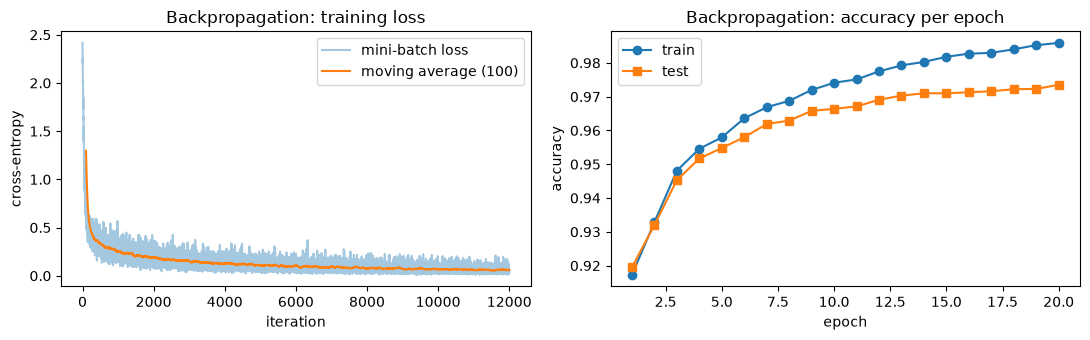

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(loss_history, alpha=0.4, label="mini-batch loss")
w = 100
ax[0].plot(np.arange(w - 1, len(loss_history)), np.convolve(loss_history, np.ones(w) / w, mode="valid"),
           label=f"moving average ({w})")
ax[0].set(title="Backpropagation: training loss", xlabel="iteration", ylabel="cross-entropy")
ax[0].legend()
epochs_ = np.arange(1, len(train_acc_history) + 1)
ax[1].plot(epochs_, train_acc_history, marker="o", label="train")
ax[1].plot(epochs_, test_acc_history, marker="s", label="test")
ax[1].set(title="Backpropagation: accuracy per epoch", xlabel="epoch", ylabel="accuracy")
ax[1].legend()
plt.tight_layout()
plt.show()


## 6. Test results (network from Experiment B)

In [12]:
pred = np.argmax(net.predict(x_test), axis=1)
correct = pred == y_test
test_accuracy = float(correct.mean())
train_accuracy = net.accuracy(x_train, t_train)
print(f"train accuracy: {train_accuracy:.4f}")
print(f"test accuracy:  {int(correct.sum())}/{len(correct)} = {test_accuracy:.4f}")

first = 20
display(pd.DataFrame({
    "test sample": np.arange(first),
    "actual": y_test[:first],
    "predicted": pred[:first],
    "result": np.where(correct[:first], "correct", "incorrect"),
}))
print(f"first {first} samples: {int(correct[:first].sum())}/{first} correct")


train accuracy: 0.9859
test accuracy:  9735/10000 = 0.9735


,test sample,actual,predicted,result
0,0,7,7,correct
1,1,2,2,correct
2,2,1,1,correct
3,3,0,0,correct
4,4,4,4,correct
5,5,1,1,correct
6,6,4,4,correct
7,7,9,9,correct
8,8,5,6,incorrect
9,9,9,9,correct


first 20 samples: 19/20 correct


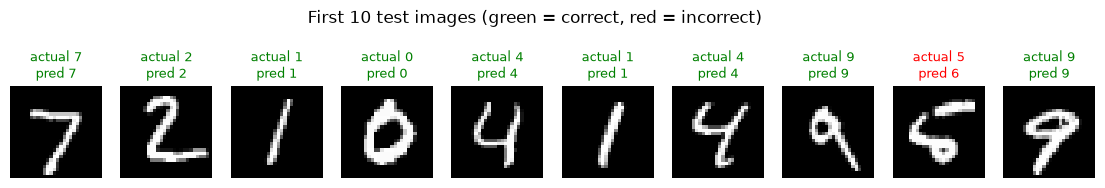

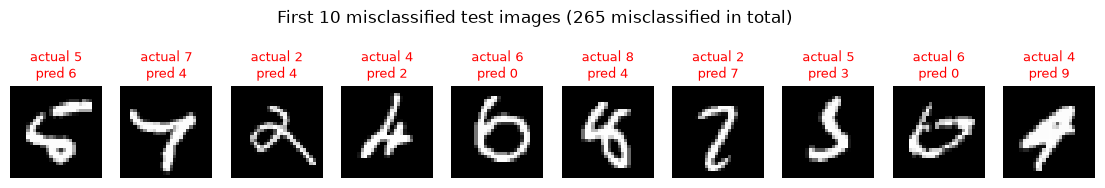

In [13]:
def show_samples(indices, title):
    fig, axes = plt.subplots(1, len(indices), figsize=(1.4 * len(indices), 2.2))
    for a, k in zip(np.atleast_1d(axes), indices):
        a.imshow(X_test[k], cmap="gray")
        ok = pred[k] == y_test[k]
        a.set_title(f"actual {y_test[k]}\npred {pred[k]}", fontsize=9, color="green" if ok else "red")
        a.axis("off")
    fig.suptitle(title, y=1.05)
    plt.show()


show_samples(range(10), "First 10 test images (green = correct, red = incorrect)")
wrong = np.flatnonzero(~correct)
show_samples(wrong[:10], f"First 10 misclassified test images ({len(wrong)} misclassified in total)")


In [14]:
per_class = pd.DataFrame({
    "digit": range(10),
    "test samples": np.bincount(y_test, minlength=10),
    "correct": np.bincount(y_test[correct], minlength=10),
})
per_class["accuracy"] = (per_class["correct"] / per_class["test samples"]).round(4)
display(per_class)

print("Confusion matrix (rows = actual, columns = predicted):")
display(pd.crosstab(pd.Series(y_test, name="actual"), pd.Series(pred, name="predicted")))


,digit,test samples,correct,accuracy
0,0,980,967,0.9867
1,1,1135,1126,0.9921
2,2,1032,998,0.9671
3,3,1010,991,0.9812
4,4,982,960,0.9776
5,5,892,862,0.9664
6,6,958,939,0.9802
7,7,1028,985,0.9582
8,8,974,935,0.9600
9,9,1009,972,0.9633


Confusion matrix (rows = actual, columns = predicted):


predicted,0,1,2,3,4,5,6,7,8,9
actual,,,,,,,,,,
0,967,0,3,1,2,1,3,1,1,1
1,0,1126,3,1,0,1,3,1,0,0
2,6,2,998,6,4,2,4,7,3,0
3,0,0,4,991,0,2,0,4,4,5
4,0,0,3,1,960,0,5,1,0,12
5,4,1,0,7,4,862,7,1,3,3
6,5,2,1,0,3,5,939,0,3,0
7,0,5,15,6,3,0,0,985,0,14
8,5,0,4,8,5,6,5,2,935,4


## 7. Summary of both approaches

In [15]:
summary = pd.DataFrame([
    {"experiment": "A", "approach": "Numerical gradient", "iterations": A_ITERS, "batch": A_BATCH,
     "training time (s)": round(time_num_A, 1),
     "train accuracy": round(net_num_A.accuracy(x_train, t_train), 4), "test accuracy": round(net_num_A.accuracy(x_test, t_test), 4)},
    {"experiment": "A", "approach": "Backpropagation", "iterations": A_ITERS, "batch": A_BATCH,
     "training time (s)": round(time_bp_A, 2),
     "train accuracy": round(net_bp_A.accuracy(x_train, t_train), 4), "test accuracy": round(net_bp_A.accuracy(x_test, t_test), 4)},
    {"experiment": "B", "approach": "Backpropagation", "iterations": B_EPOCHS * iters_per_epoch, "batch": B_BATCH,
     "training time (s)": round(time_B, 1),
     "train accuracy": round(train_accuracy, 4), "test accuracy": round(test_accuracy, 4)},
])
display(summary)


,experiment,approach,iterations,batch,training time (s),train accuracy,test accuracy
0,A,Numerical gradient,100,32,859.40,0.8404,0.8406
1,A,Backpropagation,100,32,0.05,0.8404,0.8406
2,B,Backpropagation,12000,100,16.80,0.9859,0.9735


**Reading the results**

* With the same weights, batches and learning rate, the two approaches follow the same trajectory and end with essentially the same weights and accuracy: backpropagation computes the same gradient as the numerical gradient (see the gradient check).
* Backpropagation is thousands of times faster, which is why it can train for many epochs (Experiment B) and reach a much higher accuracy than the numerical gradient can reach in a practical amount of time.